# Panjer, FFT and Monte Carlo against the benchmark of Shevchenko

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (annual loss as frequency times severity)
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- discretise a severity on a grid and say what the mass beyond the grid means;
- state the Panjer recursion for a Poisson frequency, check its first terms by hand and run it with the engine;
- compute the same distribution with the fast Fourier transform and with Monte Carlo, and say why zero padding is needed;
- reproduce the numbers printed in Shevchenko's benchmark (mean 738.9056, 99.9% quantile 5,849) and read the engine's `oprisk.benchmark_reproduction` test;
- compare the three methods on the committed true loss distribution of the synthetic bank.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import aggregate
from riskvalidation.validation import oprisk as oprisk_tests

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Two inputs. The first is **an analytic yardstick**, not a file: Example 9.4 of Shevchenko (2010), a Poisson count with mean 100 and a lognormal severity with $\mu = 0$ and $\sigma = 2$. Its mean, variance and skewness are known in closed form, and the paper prints its 99.9% quantile computed by the three methods. Any implementation of the compound distribution can be held to it, and the engine is.

The second is the committed document of case C17 for the variant with tail index 0.8:

- **File read:** `data/derived/C17/xi-0-8.json`, the row `oprisk.benchmark_reproduction` of `tests` (the yardstick as the case's bake recorded it) and the block `outputs.exceedance` (the probability that the annual loss of the synthetic bank exceeds 14 amounts, by Monte Carlo, Panjer and Fourier, with the 99.9% quantile of each).

The next cell loads the document and prints what the benchmark row holds.

In [2]:
# Load the variant document and read its benchmark row
ROOT = Path("../../..").resolve()
variant = json.loads((ROOT / "data" / "derived" / "C17" / "xi-0-8.json").read_text(encoding="utf-8"))
benchmark_row = next(row for row in variant["tests"] if row["test_id"] == "oprisk.benchmark_reproduction")
print("test_id:", benchmark_row["test_id"], "| light:", benchmark_row["light"], "| metric:", round(benchmark_row["metric"], 6))
NAMES = {"mean": "mean", "variance": "variance", "skewness": "skewness", "panjer": "panjer", "fft": "fft", "monte-carlo": "monte-carlo"}
print("deviations:", {NAMES[k]: float("%.3g" % v) for k, v in benchmark_row["extras"]["deviations"].items()})
print("gates:", benchmark_row["policy_version"])
print("baked by riskvalidation", variant["provenance"]["riskvalidation_version"])

test_id: oprisk.benchmark_reproduction | light: green | metric: 0.196688
deviations: {'mean': 1.34e-08, 'variance': 1.4e-11, 'skewness': 1.97e-06, 'panjer': 0.0, 'fft': 0.0, 'monte-carlo': 0.000111}
gates: contraste-oprisk-battery-1.0.0; moment_rel_tol=1e-05; quantile_rel_tol=0.01
baked by riskvalidation 0.7.0


## Method

The compound distribution of an annual loss $Z = \sum_{i=1}^{N} X_i$ has no closed form for a heavy-tailed severity. Three numerical methods compute it, and each is checked against the yardstick: Panjer's recursion and the fast Fourier transform work on a grid of loss amounts $0, \Delta, 2\Delta, \dots$, and Monte Carlo simulates the years.

### Step 1: discretise the severity

On a grid of step $\Delta$ the severity becomes a probability mass $f_j = P(X \approx j\Delta)$. The central discretisation, the one of the benchmark, puts at $j\Delta$ the mass of the interval centred on it (Shevchenko, 2010):

$$f_0 = F(\Delta/2), \qquad f_j = F\big((j + \tfrac12)\Delta\big) - F\big((j - \tfrac12)\Delta\big), \quad j \ge 1$$

The masses add up to at most 1. What is missing is the probability that a single loss falls beyond the last grid point; the engine reports it and never renormalises it. The next cell discretises the benchmark's lognormal on 6,000 points of step 1.

In [3]:
# Discretise the benchmark severity LN(0, 2) on 6,000 points of step 1
LAM, SEV = 100.0, (0.0, 2.0)
STEP, POINTS = 1.0, 6000
f = aggregate.discretise_severity("lognormal", SEV, STEP, POINTS)
print("f_0, f_1, f_2:", f[:3])
print("sum of the masses:", round(float(f.sum()), 9), "| mass beyond the grid:", float(1.0 - f.sum()))

f_0, f_1, f_2: [0.36445584 0.21587212 0.09624803]
sum of the masses: 0.999993184 | mass beyond the grid: 6.815706953267053e-06


### Step 2: the Panjer recursion

For a frequency of the $(a, b, 0)$ class, $p_n = (a + b/n)\,p_{n-1}$, which includes the Poisson, the compound probabilities $h_n = P(Z = n\Delta)$ obey (Panjer, 1981; Shevchenko, 2010, Theorem 5.2):

$$h_0 = \sum_{k \ge 0} f_0^{\,k}\, p_k, \qquad h_n = \frac{1}{1 - a f_0} \sum_{j=1}^{n} \left(a + \frac{b\,j}{n}\right) f_j\, h_{n-j}$$

For a Poisson($\lambda$) count, $a = 0$, $b = \lambda$ and $h_0 = e^{\lambda (f_0 - 1)}$. The next cell asks the engine for the coefficients and $h_0$, and compares $h_0$ with the formula.

In [4]:
# The coefficients (a, b) and h_0 of the Poisson case, from the engine and from the formula
a, b = aggregate.panjer_coefficients("poisson", (LAM,))
h0_engine = aggregate.panjer_h0("poisson", (LAM,), float(f[0]))
print("a =", a, "| b =", b, "| f_0 =", round(float(f[0]), 8))
print("h_0 engine:", h0_engine, "| exp(lambda * (f_0 - 1)):", float(np.exp(LAM * (f[0] - 1.0))))

a = 0.0 | b = 100.0 | f_0 = 0.36445584
h_0 engine: 2.504194378663635e-28 | exp(lambda * (f_0 - 1)): 2.504194378663635e-28


The recursion starts from $h_0$ and builds each $h_n$ from the earlier ones. With $a = 0$ the first two terms are short enough to write by hand, which checks that we read the formula as the engine does: $h_1 = \lambda f_1 h_0$ and $h_2 = \tfrac{\lambda}{2} f_1 h_1 + \lambda f_2 h_0$. The next cell runs `panjer_recursion` on the whole grid and compares its first three probabilities with those hand terms.

In [5]:
# Run the recursion on the whole grid and check its first terms against the hand formulas
h_panjer = aggregate.panjer_recursion("poisson", (LAM,), f)
h1 = LAM * f[1] * h_panjer[0]
h2 = 0.5 * LAM * f[1] * h1 + LAM * f[2] * h_panjer[0]
print("h_0, h_1, h_2 (engine):", h_panjer[:3])
print("h_1, h_2 (by hand):", h1, h2)
print("total probability on the grid:", round(float(h_panjer.sum()), 9))

h_0, h_1, h_2 (engine): [2.50419438e-28 5.40585741e-27 6.07589320e-26]
h_1, h_2 (by hand): 5.40585741249232e-27 6.07589319905883e-26
total probability on the grid: 0.999063786


### Step 3: the fast Fourier transform

The same distribution comes from transforms. The probability generating function of the frequency, $\psi(s) = E[s^N]$, applied to the discrete Fourier transform $\hat f$ of the severity masses, gives the transform of the aggregate; inverting it returns $h$ (Shevchenko, 2010, section 6.2). For a Poisson count $\psi(s) = e^{\lambda (s - 1)}$, so

$$\hat h_k = \exp\big(\lambda\,(\hat f_k - 1)\big)$$

The transform treats the grid as periodic, so mass that should lie beyond the grid wraps around to the start (aliasing). Padding the severity with zeros before transforming guards against that; the engine rounds the length to a power of two. The next cell computes $h$ with padding factors 1, 2 and 4 and prints the largest difference from the Panjer probabilities.

In [6]:
# The Fourier route with three padding factors, against the Panjer probabilities
for padding in (1, 2, 4):
    h_fft = aggregate.fft_aggregate("poisson", (LAM,), f, padding_factor=padding)
    print("padding factor", padding, "| largest difference from Panjer:", float(np.abs(h_fft - h_panjer).max()))
h_fft = aggregate.fft_aggregate("poisson", (LAM,), f, padding_factor=2)

padding factor 1 | largest difference from Panjer: 5.097631120125096e-09
padding factor 2 | largest difference from Panjer: 3.8905768255485554e-14
padding factor 4 | largest difference from Panjer: 1.235990476633475e-17


### Step 4: the 99.9% quantile of the pmf, and the erratum

From the probabilities the quantile is the smallest grid amount whose cumulative probability reaches the level: `quantile_from_pmf`. The benchmark's paper prints the cumulative probabilities beside their indices in its Table 2, and an early transcription of that table in the research behind this case attached the value 0.998999329 to index 5,849. The engine's documentation corrects it, and the cumulative sums confirm it: the value belongs to index 5,847, while index 5,849 has 0.999000217, the first at or above 0.999. The next cell prints the cumulative probability at the three indices and the quantile of both methods.

In [7]:
# The cumulative probability near the 99.9% level and the quantile of the Panjer and Fourier pmfs
cumulative = np.cumsum(h_panjer)
for index in (5847, 5848, 5849):
    print("H_%d = %.9f" % (index, cumulative[index]))
q_panjer = aggregate.quantile_from_pmf(h_panjer, STEP, 0.999)
q_fft = aggregate.quantile_from_pmf(h_fft, STEP, 0.999)
print("99.9% quantile: Panjer =", q_panjer, "| Fourier =", q_fft)

H_5847 = 0.998999329
H_5848 = 0.998999773
H_5849 = 0.999000217
99.9% quantile: Panjer = 5849.0 | Fourier = 5849.0


### Step 5: Monte Carlo

Monte Carlo draws the years instead of computing the distribution. A sample of $K$ years estimates the **continuous** quantile of $Z$, while the grid methods return the quantile of the discretised variable, so the two differ by a fraction of the step; Shevchenko's Table 3 gives 5,853.06 for the continuous quantile at a fine step. The case's bake simulates 1,000,000 years with seed 2010; the next cell does the same with the engine (about four seconds) and prints the quantile and its standard error.

In [8]:
# Simulate 1,000,000 years of the benchmark with the seed of the case's bake and read the quantile
sample = aggregate.simulate_annual_losses("poisson", (LAM,), "lognormal", SEV, 1_000_000, 2010, chunk_years=50_000)
q_mc, se_mc = aggregate.mc_quantile(sample.losses, 0.999)
print("years simulated:", sample.n_years, "| 99.9% quantile:", round(q_mc, 2), "| standard error:", round(se_mc, 1))

years simulated: 1000000 | 99.9% quantile: 5853.75 | standard error: 68.1


### Step 6: the moments

The compound Poisson sum has closed-form moments: $E[Z] = \lambda E[X]$, $\mathrm{Var}[Z] = \lambda E[X^2]$ and skewness $\lambda E[X^3] / \mathrm{Var}[Z]^{3/2}$ (Shevchenko, 2010, Example 9.4). `compound_poisson_moments` returns them. The mean of the **discretised** pmf is smaller because of the mass beyond the grid; the engine never renormalises, and its expected shortfall refuses a grid that does not carry the tail. The next cell prints the closed-form moments against the paper's, the mean of the pmf, and the mass beyond the grid next to the most that the engine's expected shortfall accepts, one thousandth of the tail probability $1 - 0.999$, that is $10^{-6}$.

In [9]:
# Closed-form moments against the published ones, and the mass beyond the grid
moments = aggregate.compound_poisson_moments(LAM, "lognormal", SEV)
published = (738.9056, 298095.7987, 40.3428)
for name, value, ref in zip(("mean", "variance", "skewness"), (moments.mean, moments.variance, moments.skewness), published):
    print("%-12s engine %.4f | published %.4f | relative difference %.2e" % (name, value, ref, abs(value - ref) / ref))
grid = np.arange(POINTS) * STEP
print("mean of the pmf on the grid:", round(float((grid * h_panjer).sum()), 4))
missing = 1.0 - float(h_panjer.sum())
allowed = round(1e-3 * (1.0 - 0.999), 12)
print("mass beyond the grid:", round(missing, 6), "| most the expected shortfall accepts (1e-3 of the tail probability):", allowed)
try:
    aggregate.es_from_pmf(h_panjer, STEP, 0.999)
except ValueError:
    print("the engine refuses the expected shortfall on this grid: it does not carry the tail")

mean         engine 738.9056 | published 738.9056 | relative difference 1.34e-08
variance     engine 298095.7987 | published 298095.7987 | relative difference 1.40e-11
skewness     engine 40.3429 | published 40.3428 | relative difference 1.97e-06
mean of the pmf on the grid: 725.7655
mass beyond the grid: 0.000936 | most the expected shortfall accepts (1e-3 of the tail probability): 1e-06
the engine refuses the expected shortfall on this grid: it does not carry the tail


### Step 7: the engine's reproduction test

`oprisk.benchmark_reproduction` takes the three moments and the three quantiles and returns one `TestResult`. A moment's deviation is its relative difference from the paper's value. A Panjer or Fourier quantile deviates by zero inside the printed range 5,849 to 5,850, and the Monte Carlo one is compared with the continuous 5,853.1. The metric is the largest deviation divided by its tolerance (`moment_rel_tol` 1e-5, `quantile_rel_tol` 0.01); it is green when the metric is at most 1, amber up to 2 and red above. These are **internal gates of the case**, descriptive and without a p-value. The tolerance on the moments must exceed the rounding of the printed skewness, 40.3428 against the exact $e^6/10 = 40.342879$. The next cell runs the test on our numbers and puts it beside the committed row.

In [10]:
# Run the reproduction test on our numbers and compare it with the committed row
test = oprisk_tests.benchmark_reproduction((moments.mean, moments.variance, moments.skewness), {"monte-carlo": q_mc, "panjer": q_panjer, "fft": q_fft}, moment_rel_tol=1e-5)
print("%-26s %14s %14s" % ("", "recomputed", "committed"))
print("%-26s %14.6f %14.6f" % ("metric", test.metric, benchmark_row["metric"]))
print("%-26s %14s %14s" % ("light", test.light.value, benchmark_row["light"]))
for name, value in test.extras["deviations"].items():
    print("%-26s %14.3e %14.3e" % ("deviation " + NAMES[name], value, benchmark_row["extras"]["deviations"][name]))
print("baked by riskvalidation", variant["provenance"]["riskvalidation_version"], "| installed", md.version("riskvalidation"))

                               recomputed      committed
metric                           0.196688       0.196688
light                               green          green
deviation mean                  1.339e-08      1.339e-08
deviation variance              1.400e-11      1.400e-11
deviation skewness              1.967e-06      1.967e-06
deviation panjer                0.000e+00      0.000e+00
deviation fft                   0.000e+00      0.000e+00
deviation monte-carlo           1.114e-04      1.114e-04
baked by riskvalidation 0.7.0 | installed 0.8.1


### Step 8: the same three methods on the bank's true loss distribution

For the synthetic bank the case committed the probability that the annual loss exceeds 14 amounts, by each method, and the 99.9% quantile. The Panjer block states its step, and the severity and frequency are the variant's true parameters, so the engine can recompute it. The next cell does so with 32,768 grid points (about five seconds), reads the exceedance curve with `exceedance_from_pmf` at the 14 amounts, and compares it with the committed Panjer block; then it prints the 99.9% quantile of the four committed methods, the fourth being the single loss approximation of notebook 04.

In [11]:
# Recompute the Panjer exceedance of the true annual loss and compare it with the committed blocks
truth = variant["outputs"]["truth"]
exceedance = variant["outputs"]["exceedance"]
lam_bank = truth["frequency"]["lambda_per_year"]
sev_bank = (truth["severity"]["tail_index"], truth["severity"]["scale_eur"], truth["severity"]["location_eur"])
step_bank = exceedance["panjer"]["step_eur"]
f_bank = aggregate.discretise_severity("gpd", sev_bank, step_bank, 32768)
h_bank = aggregate.panjer_recursion("poisson", (lam_bank,), f_bank)
nodes, sf_nodes = aggregate.exceedance_from_pmf(h_bank, step_bank)
amounts = np.array(exceedance["grid_eur"])
sf_recomputed = np.interp(amounts, nodes, sf_nodes)
committed_panjer = np.array(exceedance["panjer"]["exceedance"])
committed_fft = np.array(exceedance["fft"]["exceedance"])
committed_mc = np.array(exceedance["monte_carlo"]["exceedance"])
print("mass beyond the grid:", round(1.0 - float(h_bank.sum()), 6), "| step (EUR):", step_bank)
print("largest difference with the committed Panjer block:", float(np.abs(sf_recomputed - committed_panjer).max()))
print("largest difference Panjer - Fourier, committed:", float(np.abs(committed_panjer - committed_fft).max()))
print("largest difference Monte Carlo - Fourier, committed:", float(np.abs(committed_mc - committed_fft).max()))
for method, value in exceedance["quantile_999_eur"].items():
    print("99.9%% quantile %-12s EUR %s" % (method, format(value, ",.0f")))

mass beyond the grid: 0.00075 | step (EUR): 6236.38153
largest difference with the committed Panjer block: 5.150869730741192e-10
largest difference Panjer - Fourier, committed: 0.000695715563
largest difference Monte Carlo - Fourier, committed: 0.00019182299999997987
99.9% quantile monte_carlo  EUR 162,770,645
99.9% quantile panjer       EUR 163,486,742
99.9% quantile fft          EUR 163,483,000
99.9% quantile sla          EUR 157,682,341


The last cell draws the lessons. On the left, the probability that the benchmark's annual loss exceeds an amount, by Panjer and by the Fourier transform (they overlap), with the Monte Carlo sample as points and the 99.9% quantile marked. On the right, the exceedance of the bank's true annual loss by the three committed methods, which agree to the resolution of the plot, and below it their gap in absolute probability.

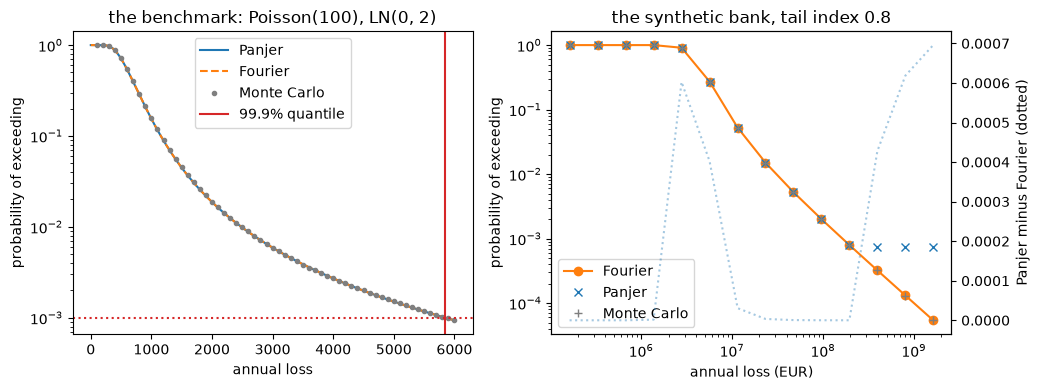

In [12]:
# Draw the benchmark exceedance and the bank's exceedance with the gap between methods
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.0))
x_pmf, sf_panjer = aggregate.exceedance_from_pmf(h_panjer, STEP)
_, sf_fft = aggregate.exceedance_from_pmf(h_fft, STEP)
left.semilogy(x_pmf[:6000:20], sf_panjer[:6000:20], color="tab:blue", label="Panjer")
left.semilogy(x_pmf[:6000:20], sf_fft[:6000:20], "--", color="tab:orange", label="Fourier")
mc_sorted = np.sort(sample.losses)
mc_x = np.linspace(100, 6000, 60)
left.semilogy(mc_x, 1.0 - np.searchsorted(mc_sorted, mc_x, side="right") / mc_sorted.size, ".", color="tab:gray", label="Monte Carlo")
left.axvline(q_panjer, color="tab:red", label="99.9% quantile")
left.axhline(0.001, color="tab:red", linestyle=":")
left.set_xlabel("annual loss")
left.set_ylabel("probability of exceeding")
left.set_title("the benchmark: Poisson(100), LN(0, 2)")
left.legend()

right.loglog(amounts, committed_fft, "o-", color="tab:orange", label="Fourier")
right.loglog(amounts, committed_panjer, "x", color="tab:blue", label="Panjer")
right.loglog(amounts, committed_mc, "+", color="tab:gray", label="Monte Carlo")
right.set_xlabel("annual loss (EUR)")
right.set_ylabel("probability of exceeding")
right.set_title("the synthetic bank, tail index 0.8")
gap = right.twinx()
gap.semilogx(amounts, committed_panjer - committed_fft, color="tab:blue", alpha=0.4, linestyle=":")
gap.set_ylabel("Panjer minus Fourier (dotted)")
right.legend(loc="lower left")
fig.tight_layout()
plt.show()

## Results

- **Discretisation.** On 6,000 points of step 1 the central masses add up to 0.999993; the mass beyond the grid is 6.8e-6, and it is reported, not renormalised.
- **Panjer.** The engine's $h_0$ equals $e^{\lambda (f_0 - 1)}$ to the last digit (2.5e-28), and its $h_1$ and $h_2$ equal the hand formulas to every digit printed. For the compound sum of 100 expected losses the grid carries 0.999064 of the probability, so 0.000936 lies beyond it.
- **Fourier.** The largest difference from Panjer is 5.1e-9 with padding factor 1, 3.9e-14 with factor 2 and 1.2e-17 with factor 4: more zero padding, less aliasing, and with factor 2 the two methods agree to 14 decimals.
- **The quantile and the erratum.** The cumulative probability is 0.998999329 at index 5,847 and 0.999000217 at index 5,849, so the 99.9% quantile is 5,849 by Panjer and by Fourier, inside the printed range 5,849 to 5,850. The value 0.998999329 belongs to index 5,847.
- **Monte Carlo.** 1,000,000 years with seed 2010 give 5,853.75 with a standard error of 68, which estimates the continuous quantile (5,853.1 in the paper); the grid methods give the quantile of the discretised variable.
- **Moments.** The closed-form mean, variance and skewness differ from the published values by 1.3e-8, 1.4e-11 and 2.0e-6, the last being the rounding of the printed 40.3428. The mean of the pmf on the grid is 725.77 against 738.91, the cost of the missing mass, and the engine refuses an expected shortfall there because 0.000936 exceeds the 1e-6 it accepts.
- **The test.** The recomputed `oprisk.benchmark_reproduction` has metric 0.196688 and is green, identical to the committed row to every printed digit, including the Monte Carlo deviation 1.114e-4: the same seed gives the same sample under riskvalidation 0.8.1 as under 0.7.0, which baked the document.
- **The bank.** The Panjer exceedance recomputed from the committed step and the true parameters matches the committed block to 5.2e-10. Panjer and Fourier differ by up to 7.0e-4 in probability between the committed blocks because their grids differ (steps of EUR 6,236 and EUR 1,000), but their 99.9% quantiles differ by 0.002%, EUR 163.487 million against EUR 163.483 million. The committed Monte Carlo quantile of 10,000,000 years is EUR 162.771 million, 0.44% below, within one standard error; the single loss approximation, EUR 157.682 million, is 3.6% below (notebook 04).

What this notebook does not show: the fits that give the severity its parameters (notebook 02), the closed-form approximation (notebook 04), or why the same capital is stable or not across histories (notebook 06 and the level 4 notebook).

## Summary

- The compound distribution of an annual loss is computed on a grid by Panjer's recursion or by the fast Fourier transform, and by simulation; the engine reproduces the published benchmark with all three.
- Panjer and Fourier agree to machine precision on the same grid; zero padding controls aliasing; mass beyond the grid is reported and never renormalised.
- Monte Carlo estimates the continuous quantile with a standard error that falls slowly; the grid methods return the quantile of the discretised variable.
- The reproduction test is an internal gate with no p-value, and the committed row is reproduced exactly by the installed engine.

**What to try next.** Change `STEP` to 0.5 and `POINTS` to 12000 and see how the quantile and the mass beyond the grid move. Replace the lognormal by the bank's generalised Pareto and watch the grid fail to carry the tail unless its extent grows. Continue with notebook 04.

## References

- Panjer, H. H. (1981), Recursive evaluation of a family of compound distributions, ASTIN Bulletin 12(1), 22-26. https://doi.org/10.1017/S0515036100006796
- Shevchenko, P. V. (2010), Calculation of aggregate loss distributions, Journal of Operational Risk 5(2), 3-40. https://arxiv.org/abs/1008.1108 and https://doi.org/10.21314/JOP.2010.077